In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.datasets import load_iris

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from sklearn.linear_model import Perceptron

In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout #drop layer to prevent overfitting
from tensorflow.keras.utils import to_categorical #(used to convert label [0,1,2] to one hot encoded [1,0,0],[0,1,1],[0,0,1])

In [4]:
# load iris
df=load_iris()


In [5]:
df=pd.DataFrame(data=df.data, columns=df.feature_names)
df['target']=load_iris().target

In [6]:
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [7]:
df['target'].value_counts()

target
0    50
1    50
2    50
Name: count, dtype: int64

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [9]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


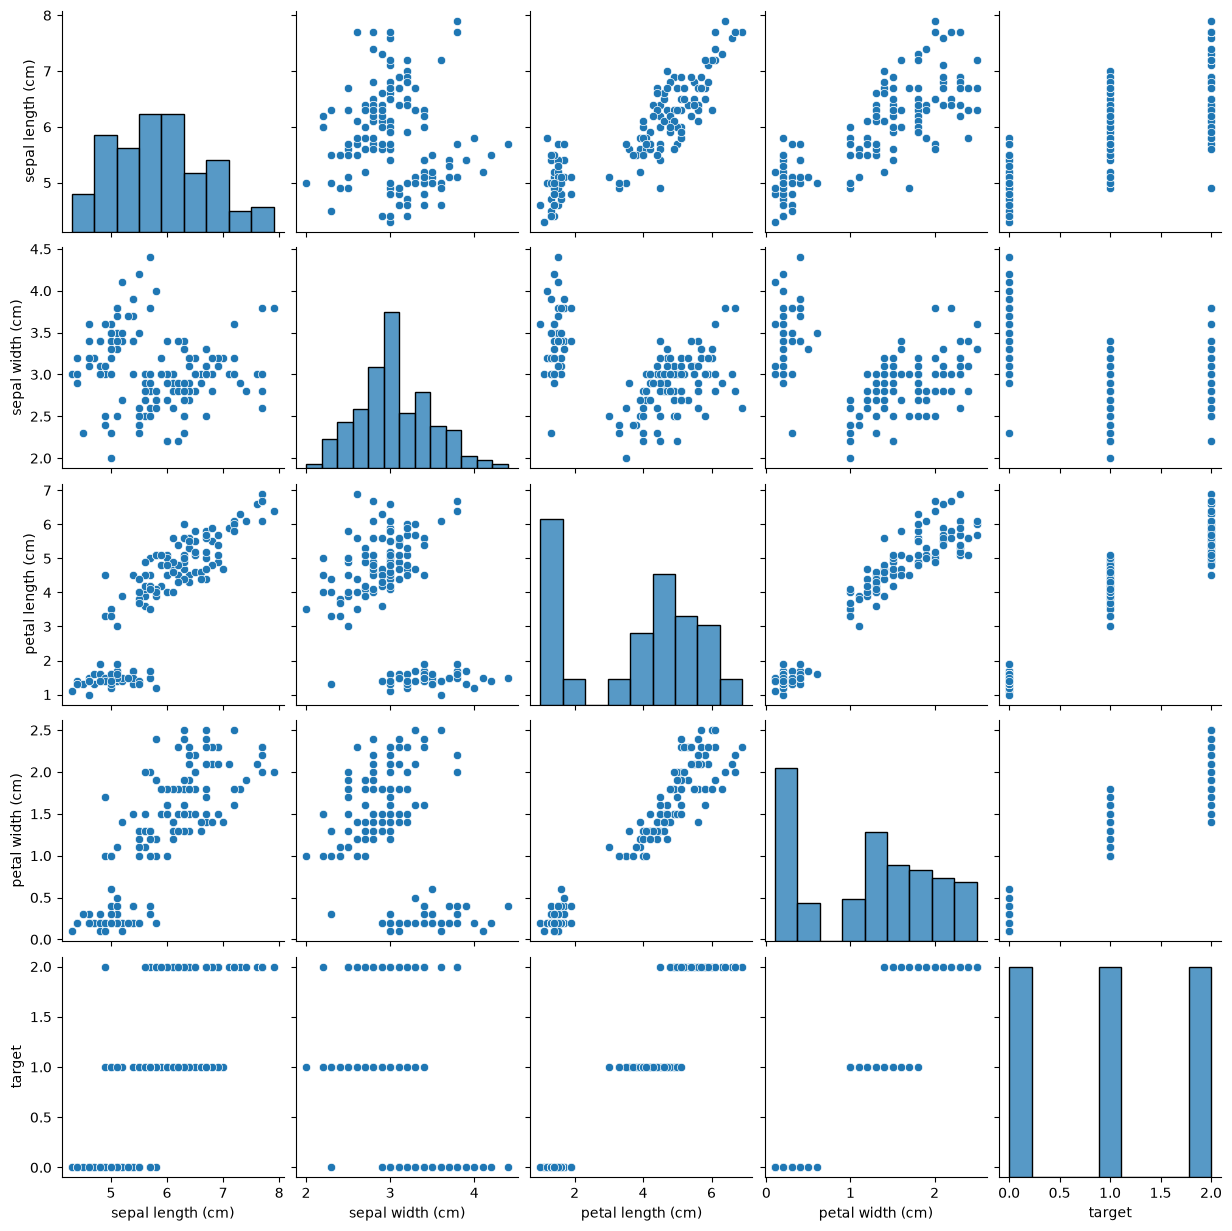

In [10]:
sns.pairplot(df)

In [11]:
X=df.drop('target',axis=1)
y=df['target']

In [12]:
X=X.astype(int)
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   sepal length (cm)  150 non-null    int64
 1   sepal width (cm)   150 non-null    int64
 2   petal length (cm)  150 non-null    int64
 3   petal width (cm)   150 non-null    int64
dtypes: int64(4)
memory usage: 4.8 KB


In [13]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,random_state=42, stratify=y)

In [14]:
# scaling
scaler=StandardScaler()
X_scaled_train=scaler.fit_transform(X_train)
X_scaled_test=scaler.fit_transform(X_test)

In [15]:
# perceptron
per=Perceptron(max_iter=1000,random_state=42)
Perceptron_model=per.fit(X_scaled_train,y_train)
Perceptron_model

,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [16]:
y_pred_per=Perceptron_model.predict(X_scaled_test)
y_pred_per

array([0, 2, 1, 1, 0, 2, 1, 2, 2, 2, 1, 2, 1, 1, 0, 0, 0, 1, 0, 1, 2, 1,
       2, 2, 2, 1, 0, 2, 0, 2, 1, 2, 0, 0, 0, 0, 2, 1])

In [17]:
accuracy_score(y_test,y_pred_per)


0.8157894736842105

In [18]:
print("classification_report:",classification_report(y_test,y_pred_per))

classification_report:               precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.75      0.69      0.72        13
           2       0.71      0.77      0.74        13

    accuracy                           0.82        38
   macro avg       0.82      0.82      0.82        38
weighted avg       0.82      0.82      0.82        38



ANN

In [19]:
# one hot encoding

y_train_categorical=to_categorical(y_train, num_classes=3)
y_test_categorical=to_categorical(y_test,num_classes=3)

In [20]:
model=Sequential(
    [
        Dense(16,input_dim=4, activation='relu'),
        Dense(8,activation='relu'),
        Dense(3,activation='softmax')
    ]
)

In [21]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'],
    
    )

In [22]:
history=model.fit(X_scaled_train,y_train_categorical, epochs=100, batch_size=8, validation_split=.2,verbose=1 )

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.7303 - loss: 1.0631 - val_accuracy: 0.6522 - val_loss: 1.0399
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7416 - loss: 1.0328 - val_accuracy: 0.6522 - val_loss: 1.0097
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7865 - loss: 0.9974 - val_accuracy: 0.6957 - val_loss: 0.9703
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7865 - loss: 0.9593 - val_accuracy: 0.6957 - val_loss: 0.9303
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7978 - loss: 0.9154 - val_accuracy: 0.7391 - val_loss: 0.8834
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7978 - loss: 0.8684 - val_accuracy: 0.7826 - val_loss: 0.8339
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8202 - loss: 0.8208 - val_accuracy: 0.7826 - val_loss: 0.7911
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8202 - loss: 0.7817 - val_accuracy: 0.

In [23]:
# model accuracy 
loss,acc=model.evaluate(X_scaled_test,y_test_categorical, verbose=0)
print(acc)
# print(loss)

0.8947368264198303


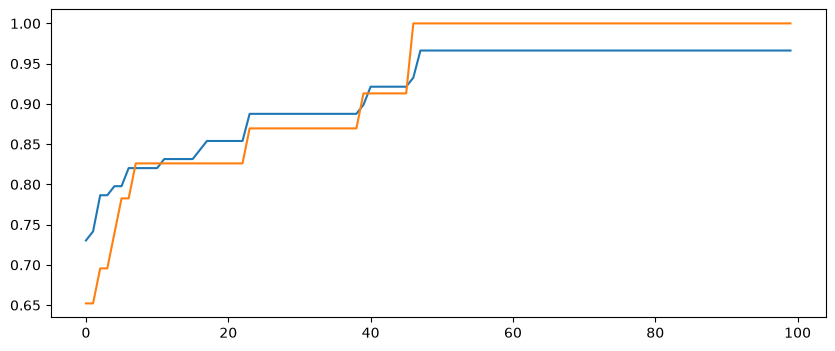

In [24]:
plt.figure(figsize=(10,4))
plt.plot(history.history['accuracy'], label='Train accuracy')
plt.plot(history.history['val_accuracy'], label='val accuracy')